# ЛР № 4. Аналитическая витрина `mart.energy_balance`

**Вход:** `staging.parquet`, подготовленный в ЛР № 3 (`s3://staging/owid_energy/source_ingested_on=2026-10-06/`).
**Выход:** `s3://mart/owid_energy/source_ingested_on=2026-10-06/energy_balance.parquet`.

**Выбранный вопрос (основной вопрос `Project Brief`).**
Как изменялись объём потребления энергии и структура энергетического баланса в мире и отдельных
регионах с течением времени?

**Что нужно витрине для ответа.** Одна строка должна давать: страну или регион, год, объём первичного
потребления, население и ВВП для нормировки, состав баланса (доли угля, нефти, газа, ядерной и
возобновляемой энергии) и признаки, по которым видно, что показатель за эту строку отсутствует
в источнике или строка является агрегатом, а не страной. Поэтому витрина строится на уровне
отдельного наблюдения «страна × год»; агрегаты и тренды считаются SQL-запросами поверх неё.

**Источник решений о качестве** — `docs/data_quality_report.md` (ЛР № 3): в `staging` нет строк
с годом вне 1900–2025, отрицательным потреблением и пустым названием страны; строк с флагом
`flag_inconsistent_capita` нет.

## 1. Параметры запуска

In [1]:
DATASET_SLUG = "owid_energy"
LOGICAL_DATE = "2026-10-06"       # совпадает с source_ingested_on входного staging
MART_NAME = "energy_balance"      # смысл: одна строка - страна/регион за один год

STAGING_URI = f"s3://staging/{DATASET_SLUG}/source_ingested_on={LOGICAL_DATE}/staging.parquet"
MART_URI = f"s3://mart/{DATASET_SLUG}/source_ingested_on={LOGICAL_DATE}/{MART_NAME}.parquet"

for name in ["STAGING_URI", "MART_URI"]:
    print(f"{name:12} = {globals()[name]}")

STAGING_URI  = s3://staging/owid_energy/source_ingested_on=2026-10-06/staging.parquet
MART_URI     = s3://mart/owid_energy/source_ingested_on=2026-10-06/energy_balance.parquet


## 2. Подключение и проверка входного `staging`

In [2]:
import os
from pathlib import Path

import duckdb
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

root = Path.cwd()
while not (root / ".env").exists() and root.parent != root:
    root = root.parent
load_dotenv(root / ".env")

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute(
    f"""
    CREATE OR REPLACE SECRET seaweedfs (
        TYPE s3,
        KEY_ID '{os.environ["S3_ACCESS_KEY"]}',
        SECRET '{os.environ["S3_SECRET_KEY"]}',
        ENDPOINT '{os.environ["S3_ENDPOINT"]}',
        URL_STYLE 'path',
        USE_SSL false,
        REGION 'us-east-1'
    )
    """
)


def sql(query: str) -> pd.DataFrame:
    return con.execute(query).df()


print("DuckDB:", duckdb.__version__, "| S3 endpoint:", os.environ["S3_ENDPOINT"])

DuckDB: 1.1.3 | S3 endpoint: localhost:8333


In [3]:
staging_info = sql(f"""
SELECT count(*)                                      AS staging_rows,
       count(DISTINCT country)                       AS distinct_countries,
       min(year)                                     AS min_year,
       max(year)                                     AS max_year,
       sum(CASE WHEN primary_energy_consumption IS NULL THEN 1 ELSE 0 END) AS null_primary_energy,
       sum(CASE WHEN iso_code IS NULL THEN 1 ELSE 0 END)                   AS aggregate_rows,
       sum(CASE WHEN flag_inconsistent_capita THEN 1 ELSE 0 END)           AS flagged_rows
FROM read_parquet('{STAGING_URI}')
""")
display(staging_info)

display(sql(f"DESCRIBE SELECT * FROM read_parquet('{STAGING_URI}')").head(12))
print("...")

,staging_rows,distinct_countries,min_year,max_year,null_primary_energy,aggregate_rows,flagged_rows
0,23377,314,1900,2025,10122.0,6112.0,0.0


,column_name,column_type,null,key,default,extra
0,country,VARCHAR,YES,None,None,None
1,year,BIGINT,YES,None,None,None
2,iso_code,VARCHAR,YES,None,None,None
3,population,BIGINT,YES,None,None,None
4,gdp,BIGINT,YES,None,None,None
5,biofuel_cons_change_pct,DOUBLE,YES,None,None,None
6,biofuel_cons_change_twh,DOUBLE,YES,None,None,None
7,biofuel_cons_per_capita,DOUBLE,YES,None,None,None
8,biofuel_consumption,DOUBLE,YES,None,None,None
9,biofuel_elec_per_capita,DOUBLE,YES,None,None,None


...


**Ограничения качества, влияющие на показатели (из ЛР № 3).**

- `primary_energy_consumption` пуст в 10 122 строках (43 %): это ранние годы, часть стран и весь
  2025 год. Пропуск означает «в источнике нет измерения», а не ноль, поэтому такие строки
  сохраняются и помечаются вычисляемым признаком `has_primary_energy`.
- В наборе 94 агрегата (`World`, `ASEAN (Ember)`, регионы) — у них нет `iso_code`. Смешивать их
  со странами нельзя: сумма по странам и значение агрегата — разные величины. Для этого в витрине
  есть `is_aggregate`.
- Флаг `flag_inconsistent_capita` (правило `R4` ЛР № 3) переносится без изменения значений, даже если
  строк с ним нет.
- Ключ `(country, year)` в ЛР № 3 признан уникальным: 23 377 строк, 0 повторов. Это единственный
  настоящий бизнес-ключ в работе, и он сохраняется в витрине.

## 3. Гранулярность, ключ и меры

> Одна строка таблицы `energy_balance` представляет одно наблюдение «страна или регион × год»
> из снимка OWID Energy (`raw` от 2026-10-06), прошедшее решения о качестве ЛР № 3.

**Ключ.** `(country, year)` — естественный составной ключ. Он проверен на пропуски и повторы
в разделе 6; строки не удаляются и `DISTINCT` не применяется, потому что гранулярность задана
источником.

**Меры витрины и правила их агрегации.**

| Мера | Единица | Использование в вопросе | Можно ли суммировать |
| --- | --- | --- | --- |
| `count(*)` (`observations`) | наблюдения | покрытие данных по годам и странам | да, по непересекающимся срезам |
| `sum(primary_energy_consumption)` | ТВт·ч | объём потребления в срезе | да по странам внутри года, **нельзя** складывать страны и агрегаты |
| `avg(energy_per_capita)` | кВт·ч/чел. | сравнение стран | нет: средние по странам требуют веса `population` |
| `renewables_share_energy` и другие доли | % | структура баланса | нет: доли не складываются, средняя доля — только взвешенная по потреблению |
| `sum(population)`, `sum(gdp)` | чел., межд. $ | нормировка и сравнение | да по странам внутри года, не суммировать с агрегатами |
| `avg(carbon_intensity_elec)` | г CO₂/кВт·ч | интенсивность электроэнергетики | только с весом по выработке |

Доли в источнике уже нормированы на первичное потребление; проверка в разделе 6 показывает, что
сумма девяти долей по видам топлива равна 100 % в каждой строке, где они заполнены, поэтому доли
можно сравнивать между странами и годами напрямую.

In [4]:
display(sql(f"""
SELECT round(min(primary_energy_consumption), 2) AS min_energy,
       round(max(primary_energy_consumption), 2) AS max_energy,
       round(min(energy_per_capita), 2)          AS min_energy_pc,
       round(max(energy_per_capita), 2)          AS max_energy_pc,
       round(min(renewables_share_energy), 2)    AS min_renewables_share,
       round(max(renewables_share_energy), 2)    AS max_renewables_share,
       round(min(fossil_share_energy), 2)        AS min_fossil_share,
       round(max(fossil_share_energy), 2)        AS max_fossil_share
FROM read_parquet('{STAGING_URI}')
"""))

,min_energy,max_energy,min_energy_pc,max_energy_pc,min_renewables_share,max_renewables_share,min_fossil_share,max_fossil_share
0,0.0,176737.09,0.0,651836.56,0.0,86.13,13.87,100.0


## 4. Структура витрины

Выбрана **одна широкая таблица `energy_balance`, без отдельных таблиц измерений**.

Обоснование:

- источник уже представляет собой денормализованную панель «страна × год»: название страны и её
  `iso_code` находятся в той же строке, отдельной сущности, которую нужно было бы нормализовать,
  в наборе нет;
- вопрос требует только срезов по стране/региону и году, справочников для расшифровки кодов нет
  (`iso_code` — и есть расшифровка страны);
- раз в модели нет `JOIN`, нет и риска размножения строк, а проверки кардинальности сводятся
  к проверке ключа `(country, year)`.

Отдельная таблица измерения понадобилась бы, если бы появился внешний справочник (например,
«страна → континент → доходная группа»); для текущего вопроса это лишняя сущность.

## 5. Сборка витрины `energy_balance`

Поля перечислены явно. Вычисления:

- `decade` — десятилетие года наблюдения, для срезов «по десятилетиям»;
- `is_aggregate` — признак агрегата (`iso_code IS NULL`): `World`, регионы, группы стран;
- `has_primary_energy` — признак наличия измерения потребления в этой строке;
- остальные поля — перенос без изменения значений; доли и потребление уже нормированы в источнике
  (ТВт·ч, кВт·ч/чел., %), поэтому новых пересчётов не требуется;
- `source_ingested_on` — логическая дата загрузки снимка из пути объекта, а не дата события.

Фильтрации нет: витрина сохраняет все 23 377 строк `staging`. Пропуски потребления не удаляются,
потому что пропуск — это отсутствие измерения, а не ошибка; решение о качестве по этим строкам уже
принято в ЛР № 3.

In [5]:
mart_sql = f"""
SELECT
    country,
    iso_code,
    year::INTEGER                                    AS year,
    ((year // 10) * 10)::INTEGER                     AS decade,
    (iso_code IS NULL)                               AS is_aggregate,
    (primary_energy_consumption IS NOT NULL)         AS has_primary_energy,
    population::DOUBLE                               AS population,
    gdp::DOUBLE                                      AS gdp,
    primary_energy_consumption,
    energy_per_capita,
    energy_per_gdp,
    electricity_generation,
    electricity_demand,
    per_capita_electricity,
    fossil_fuel_consumption,
    renewables_consumption,
    low_carbon_consumption,
    nuclear_consumption,
    coal_share_energy,
    oil_share_energy,
    gas_share_energy,
    nuclear_share_energy,
    hydro_share_energy,
    wind_share_energy,
    solar_share_energy,
    biofuel_share_energy,
    other_renewables_share_energy,
    fossil_share_energy,
    renewables_share_energy,
    low_carbon_share_energy,
    carbon_intensity_elec,
    greenhouse_gas_emissions,
    flag_inconsistent_capita,
    source_ingested_on
FROM read_parquet('{STAGING_URI}')
"""

con.execute(f"CREATE OR REPLACE VIEW mart_energy_v AS {mart_sql}")
display(sql("SELECT * FROM mart_energy_v LIMIT 3"))

,country,iso_code,year,decade,is_aggregate,has_primary_energy,population,gdp,primary_energy_consumption,energy_per_capita,energy_per_gdp,electricity_generation,electricity_demand,per_capita_electricity,fossil_fuel_consumption,renewables_consumption,low_carbon_consumption,nuclear_consumption,coal_share_energy,oil_share_energy,gas_share_energy,nuclear_share_energy,hydro_share_energy,wind_share_energy,solar_share_energy,biofuel_share_energy,other_renewables_share_energy,fossil_share_energy,renewables_share_energy,low_carbon_share_energy,carbon_intensity_elec,greenhouse_gas_emissions,flag_inconsistent_capita,source_ingested_on
0,Syria,SYR,2003,2000,False,True,17889297.0,1.225016e+11,220.854,12345.578,1.803,30.40,30.15,1699.340,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,667.76,20.30,False,2026-10-06
1,Syria,SYR,2004,2000,False,True,18336879.0,1.265153e+11,243.686,13289.391,1.926,32.17,31.62,1754.388,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,630.71,20.29,False,2026-10-06
2,Syria,SYR,2005,2000,False,True,18814092.0,1.296570e+11,276.080,14674.131,2.129,36.08,35.41,1917.712,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,634.15,22.88,False,2026-10-06


In [6]:
balance = sql(f"""
SELECT
    (SELECT count(*) FROM read_parquet('{STAGING_URI}')) AS staging_rows,
    (SELECT count(*) FROM mart_energy_v)                 AS mart_rows,
    (SELECT count(*) FROM read_parquet('{STAGING_URI}')) -
    (SELECT count(*) FROM mart_energy_v)                 AS excluded_rows
""")
display(balance)
assert balance.excluded_rows[0] == 0, "витрина потеряла или добавила строки"

,staging_rows,mart_rows,excluded_rows
0,23377,23377,0


## 6. Материализация в `mart`

Запись выполняется в Parquet; повторный запуск перезаписывает объект предыдущего выполнения,
а не добавляет новые файлы.

In [7]:
con.execute(f"COPY (SELECT * FROM mart_energy_v) TO '{MART_URI}' (FORMAT parquet, COMPRESSION zstd)")
display(sql(f"SELECT count(*) AS mart_rows FROM read_parquet('{MART_URI}')"))
print("mart ->", MART_URI)

,mart_rows
0,23377


mart -> s3://mart/owid_energy/source_ingested_on=2026-10-06/energy_balance.parquet


## 7. Проверки записанного результата

Все проверки выполняются на объекте, прочитанном из `mart`, а не на таблицах в памяти.

### 7.1. Количество строк и схема

In [8]:
counts = sql(f"""
SELECT (SELECT count(*) FROM read_parquet('{STAGING_URI}')) AS staging_rows,
       (SELECT count(*) FROM read_parquet('{MART_URI}'))    AS mart_rows
""")
display(counts)
assert counts.staging_rows[0] == counts.mart_rows[0], "число строк изменилось"

display(sql(f"DESCRIBE SELECT * FROM read_parquet('{MART_URI}')")[["column_name", "column_type"]])

,staging_rows,mart_rows
0,23377,23377


,column_name,column_type
0,country,VARCHAR
1,iso_code,VARCHAR
2,year,INTEGER
3,decade,INTEGER
4,is_aggregate,BOOLEAN
5,has_primary_energy,BOOLEAN
6,population,DOUBLE
7,gdp,DOUBLE
8,primary_energy_consumption,DOUBLE
9,energy_per_capita,DOUBLE


### 7.2. Ключ и обязательные поля

In [9]:
key_check = sql(f"""
WITH m AS (SELECT * FROM read_parquet('{MART_URI}')),
     k AS (SELECT country, year, count(*) AS rows_per_key FROM m GROUP BY ALL)
SELECT (SELECT count(*) FROM m)                                        AS rows_total,
       (SELECT count(*) FROM k)                                        AS distinct_keys,
       (SELECT count(*) FROM m WHERE country IS NULL OR TRIM(country) = '') AS null_country,
       (SELECT count(*) FROM m WHERE year IS NULL)                      AS null_year,
       (SELECT sum(rows_per_key) - count(*) FROM k)                    AS redundant_rows,
       (SELECT count(*) FROM k WHERE rows_per_key > 1)                 AS keys_with_repeats
""")
display(key_check.T)
assert key_check.redundant_rows[0] == 0, "ключ (country, year) не уникален"
assert key_check.null_country[0] == 0 and key_check.null_year[0] == 0

,0
rows_total,23377.0
distinct_keys,23377.0
null_country,0.0
null_year,0.0
redundant_rows,0.0
keys_with_repeats,0.0


### 7.3. Меры и вычисленные поля

In [10]:
measures = sql(f"""
SELECT count(*)                                                       AS rows_total,
       sum(CASE WHEN primary_energy_consumption IS NULL THEN 1 ELSE 0 END)  AS null_primary_energy,
       sum(CASE WHEN has_primary_energy IS NULL THEN 1 ELSE 0 END)          AS null_has_primary_energy,
       sum(CASE WHEN has_primary_energy
                 AND primary_energy_consumption IS NULL THEN 1 ELSE 0 END)  AS flag_conflicts_with_value,
       sum(CASE WHEN NOT has_primary_energy
                 AND primary_energy_consumption IS NOT NULL THEN 1 ELSE 0 END) AS value_conflicts_with_flag,
       round(min(primary_energy_consumption), 2)                        AS min_energy,
       round(max(primary_energy_consumption), 2)                        AS max_energy,
       round(min(energy_per_capita), 2)                                 AS min_energy_per_capita,
       round(max(energy_per_capita), 2)                                 AS max_energy_per_capita,
       sum(CASE WHEN is_aggregate IS NULL THEN 1 ELSE 0 END)            AS null_is_aggregate
FROM read_parquet('{MART_URI}')
""")
display(measures.T)
assert measures.flag_conflicts_with_value[0] == 0
assert measures.value_conflicts_with_flag[0] == 0

,0
rows_total,23377.00
null_primary_energy,10122.00
null_has_primary_energy,0.00
flag_conflicts_with_value,0.00
value_conflicts_with_flag,0.00
min_energy,0.00
max_energy,176737.09
min_energy_per_capita,0.00
max_energy_per_capita,651836.56
null_is_aggregate,0.00


In [11]:
ranges = sql(f"""
SELECT min(year)                                                  AS min_year,
       max(year)                                                  AS max_year,
       count(DISTINCT year)                                       AS distinct_years,
       min(decade)                                                AS min_decade,
       max(decade)                                                AS max_decade,
       sum(CASE WHEN year < 1900 OR year > 2025 THEN 1 ELSE 0 END) AS bad_year,
       sum(CASE WHEN decade > year THEN 1 ELSE 0 END)              AS bad_decade,
       round(min(coal_share_energy), 2)                           AS min_coal_share,
       round(max(coal_share_energy), 2)                           AS max_coal_share,
       round(min(renewables_share_energy), 2)                     AS min_renewables_share,
       round(max(renewables_share_energy), 2)                     AS max_renewables_share,
       round(min(fossil_share_energy), 2)                         AS min_fossil_share,
       round(max(fossil_share_energy), 2)                         AS max_fossil_share,
       sum(CASE WHEN renewables_share_energy < 0
                  OR renewables_share_energy > 100 THEN 1 ELSE 0 END) AS bad_renewables_share,
       sum(CASE WHEN fossil_share_energy < 0
                  OR fossil_share_energy > 100 THEN 1 ELSE 0 END)     AS bad_fossil_share
FROM read_parquet('{MART_URI}')
""")
display(ranges.T)
assert ranges.bad_year[0] == 0 and ranges.bad_decade[0] == 0
assert ranges.bad_renewables_share[0] == 0 and ranges.bad_fossil_share[0] == 0

display(sql(f"""
SELECT count(*) AS rows_with_full_balance,
       round(min(total), 2) AS min_share_sum,
       round(max(total), 2) AS max_share_sum
FROM (SELECT coal_share_energy + oil_share_energy + gas_share_energy + nuclear_share_energy
             + hydro_share_energy + wind_share_energy + solar_share_energy
             + biofuel_share_energy + other_renewables_share_energy AS total
      FROM read_parquet('{MART_URI}')
      WHERE coal_share_energy IS NOT NULL AND gas_share_energy IS NOT NULL)
"""))

,0
min_year,1900.00
max_year,2025.00
distinct_years,126.00
min_decade,1900.00
max_decade,2020.00
bad_year,0.00
bad_decade,0.00
min_coal_share,0.00
max_coal_share,89.16
min_renewables_share,0.00


,rows_with_full_balance,min_share_sum,max_share_sum
0,6379,100.0,100.0


Проверка суммы долей подтверждает, что структура баланса в витрине согласована: там, где заполнены
все девять видов топлива, сумма долей равна 100 %. Это же значение служит ориентиром при чтении
диаграмм структуры.

### 7.4. Флаги качества и преобразования

In [12]:
flags = sql(f"""
SELECT 'mart' AS source,
       sum(CASE WHEN flag_inconsistent_capita THEN 1 ELSE 0 END) AS flagged,
       count(*)                                                  AS rows_total
FROM read_parquet('{MART_URI}')
UNION ALL
SELECT 'staging',
       sum(CASE WHEN flag_inconsistent_capita THEN 1 ELSE 0 END),
       count(*)
FROM read_parquet('{STAGING_URI}')
""")
display(flags)

aggregate_check = sql(f"""
SELECT count(*) AS aggregate_rows,
       count(DISTINCT country) AS aggregates,
       (SELECT count(*) FROM read_parquet('{MART_URI}') WHERE NOT is_aggregate) AS country_rows,
       (SELECT count(DISTINCT country) FROM read_parquet('{MART_URI}') WHERE NOT is_aggregate) AS countries
FROM read_parquet('{MART_URI}') WHERE is_aggregate
""")
display(aggregate_check)

,source,flagged,rows_total
0,mart,0.0,23377
1,staging,0.0,23377


,aggregate_rows,aggregates,country_rows,countries
0,6112,94,17265,220


### 7.5. Пригодность для выбранного вопроса

In [13]:
display(sql(f"""
SELECT year, primary_energy_consumption, renewables_share_energy, fossil_share_energy
FROM read_parquet('{MART_URI}')
WHERE country = 'World' AND has_primary_energy
ORDER BY year DESC
LIMIT 8
"""))

display(sql(f"""
SELECT country, primary_energy_consumption, energy_per_capita,
       renewables_share_energy, fossil_share_energy
FROM read_parquet('{MART_URI}')
WHERE year = 2023 AND NOT is_aggregate AND has_primary_energy
ORDER BY primary_energy_consumption DESC
LIMIT 10
"""))

,year,primary_energy_consumption,renewables_share_energy,fossil_share_energy
0,2024,176737.094,14.822,81.257
1,2023,172238.781,13.943,82.148
2,2022,169061.531,13.504,82.573
3,2021,166043.500,12.861,82.950
4,2020,157993.891,12.781,82.985
5,2019,163694.609,11.651,84.092
6,2018,161806.125,11.202,84.619
7,2017,157625.312,10.793,84.997


,country,primary_energy_consumption,energy_per_capita,renewables_share_energy,fossil_share_energy
0,China,47072.012,33089.070,15.505,82.220
1,United States,26216.545,76326.859,11.212,81.147
2,India,10827.859,7529.440,8.861,90.047
3,Russia,8760.904,60237.031,5.913,88.004
4,Japan,4858.530,39064.832,11.965,84.119
5,Canada,3887.860,98930.016,27.858,66.492
6,Brazil,3853.746,18252.027,48.950,50.109
7,Iran,3596.104,39688.281,1.680,97.870
8,South Korea,3557.898,68753.328,4.660,82.906
9,Saudi Arabia,3200.741,96221.539,0.359,99.641


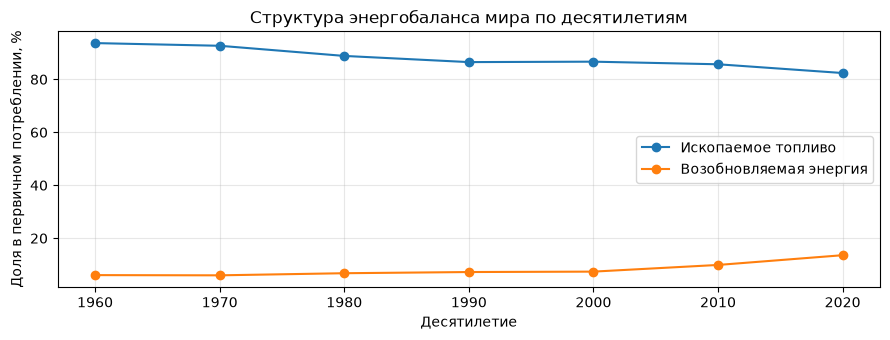

In [14]:
import matplotlib.pyplot as plt

world = sql(f"""
SELECT decade,
       avg(fossil_share_energy)     AS fossil_share_energy,
       avg(renewables_share_energy) AS renewables_share_energy
FROM read_parquet('{MART_URI}')
WHERE country = 'World' AND has_primary_energy
GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(world.decade, world.fossil_share_energy, marker="o", label="Ископаемое топливо")
ax.plot(world.decade, world.renewables_share_energy, marker="o", label="Возобновляемая энергия")
ax.set_xlabel("Десятилетие")
ax.set_ylabel("Доля в первичном потреблении, %")
ax.set_title("Структура энергобаланса мира по десятилетиям")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

Запросы подтверждают пригодность витрины: по каждой строке восстанавливаются страна, год, объём
потребления и доли видов топлива, поэтому группировка по году, десятилетию или стране даёт и объём,
и структуру баланса без обращения к исходному файлу. Полный набор метрик и содержательные выводы —
задача следующей работы.

### 7.6. Итог проверок

In [15]:
summary = pd.DataFrame(
    [
        ("Строк во входном staging", int(counts.staging_rows[0])),
        ("Строк в витрине energy_balance", int(counts.mart_rows[0])),
        ("Исключено строк (баланс)", int(balance.excluded_rows[0])),
        ("Различных ключей (country, year)", int(key_check.distinct_keys[0])),
        ("Повторных ключей", int(key_check.keys_with_repeats[0])),
        ("Строк без измерения потребления", int(measures.null_primary_energy[0])),
        ("Строк-агрегатов (World, регионы)", int(aggregate_check.aggregate_rows[0])),
        ("Строк-стран", int(aggregate_check.country_rows[0])),
        ("Различных лет", int(ranges.distinct_years[0])),
        ("Строк с флагом ЛР № 3", int(flags.loc[flags['source'] == 'mart', 'flagged'].iloc[0])),
    ],
    columns=["проверка", "значение"],
)
display(summary)

assert counts.staging_rows[0] == counts.mart_rows[0]
print("Все обязательные проверки пройдены: гранулярность и число строк сохранены, ключ уникален, флаги сверены.")

,проверка,значение
0,Строк во входном staging,23377
1,Строк в витрине energy_balance,23377
2,Исключено строк (баланс),0
3,"Различных ключей (country, year)",23377
4,Повторных ключей,0
5,Строк без измерения потребления,10122
6,"Строк-агрегатов (World, регионы)",6112
7,Строк-стран,17265
8,Различных лет,126
9,Строк с флагом ЛР № 3,0


Все обязательные проверки пройдены: гранулярность и число строк сохранены, ключ уникален, флаги сверены.
